# CrusherBayes held out on the ten surveys: the predictive intervals against the CrusherCal band, what the surveys identify and the kill criterion applied as written

**Question:** Does CrusherBayes, the Bayesian calibration of the engine with a structural discrepancy, predict a held-out survey better than the setting-only line B-lin and give a sharper, calibrated interval than the CrusherCal band, and does the criterion written before the run keep or drop it?

- **Level:** 4, the product's proposed method
- **Prerequisites:** notebooks 01 and 02 of this topic and notebook 04 of topic 06
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- say what CrusherBayes claims over the single calibrated point of the paper, and what result would drop it, stated before the run;
- score its held-out predictions and 80 percent intervals on the ten surveys against B-lin, the backbone, the free-form regression and the CrusherCal band;
- read the contraction table to say which parameters the ten surveys identify and which stay at their prior;
- apply the kill criterion from the numbers computed here, compare it with the committed verdict, and say what the convergence record shows.

## Setup

Numpy and matplotlib; the CrusherBayes module is imported for its kill-criterion function, and its sampler is not run here (notebook 02 ran it live).

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the backbone builder, the CrusherCal functions and the CrusherBayes module.

In [1]:

# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo, crusherbayes as cb
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, `VERSION`, and `data/derived/hp500/crusherbayes.json`. That document holds the ten-fold result of the full-length sampler, which takes about 45 minutes to run and is baked offline; **the CrusherBayes numbers of this notebook are read from it and scored here, and are not a live run**. The CrusherCal band and the comparators are computed live.

The cell reads the surveys, builds CrusherCal's held-out document live and loads the committed one.

In [2]:

# The surveys, the backbone and CrusherCal's held-out document built live, and the committed
# CrusherBayes document
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
crushercal = loo.build(backbone.build(surveys, version), version)
committed = json.loads((ROOT / "data/derived/hp500/crusherbayes.json").read_text(encoding="utf-8"))
record = committed["convergence"]["folds"]
text = (
    'surveys: {} | release label: {} | committed chains: {} steps, '
    'converged {} of {} posteriors'
)
passed = sum(c["converged"] for c in record)
print(text.format(len(surveys), version, committed["method"]["steps"], passed, len(record)))


surveys: 10 | release label: 0.11.000 | committed chains: 7000 steps, converged 11 of 11 posteriors


## Method

**The claim and the rule that tests it.** The calibration of Rocha et al. (2024) is a point fit. CrusherBayes puts a posterior over the engine's eight fitted scalars, adds a low-order structural discrepancy per target (Kennedy and O'Hagan, 2001), and refits it without each held-out survey. The design document states the hypothesis and its kill criterion before the run: the method is dropped as a predictor if (a) its power error is not below B-lin's by at least 3 points and its throughput error does not beat the backbone's by the same margin, and (b) on either target its coverage lies outside 0.7 to 0.9 or its band is wider than the CrusherCal band. Three points of MAPE is the margin because at ten surveys a smaller difference is noise. The notebook scores everything the rule needs, then applies the rule.

**CrusherCal's band.** The comparison band is the one the product already ships: the backbone's held-out prediction plus or minus 1.2816 times the nested sigma, in which each survey's sigma comes from the residuals of the other nine (notebook 04 of topic 06). The cell builds it for both targets from the live CrusherCal document.

In [3]:

# CrusherCal's 80 percent band per survey: the backbone's held-out prediction plus or minus 1.2816
# times the nested sigma
targets = (("tph", "tph"), ("kW", "kW"))
cc_band = {}
for name, key in targets:
    strict = crushercal["loo"][key]["strict"]
    measured = np.array(crushercal["loo"][key]["measured"])
    pred = np.array(strict["pred"]["M0"])
    nested = loo.nested_band_coverage(measured - pred)
    half = loo.band_factor(0.8) * np.array(nested["sigma"])
    cc_band[name] = (pred - half, pred + half)
    outside = np.flatnonzero(~np.array(nested["covered"])) + 1
    print((
    '{:5s} CrusherCal band: coverage {:.2f}, mean width {:7.1f}, '
    'outside: survey {}'
).format(name, nested["coverage"], np.mean(2 * half), outside))


tph   CrusherCal band: coverage 0.80, mean width   473.8, outside: survey [1 6]
kW    CrusherCal band: coverage 0.90, mean width   209.8, outside: survey [7]


## Comparison

The next cell scores CrusherBayes on the same footing: the posterior predictive mean of each held-out survey from the committed document against the measurement, the share of surveys inside its own 80 percent interval, and the mean width of that interval.

In [4]:

# CrusherBayes's held-out predictions and 80 percent intervals, from the committed document, scored
# here
cb_score = {}
for name, key in targets:
    block = committed["loo"][name]
    measured = np.array(block["measured"])
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    inside = (measured >= lo) & (measured <= hi)
    mape = loo.mape(measured, np.array(block["pred_mean"]))
    cb_score[name] = {"mape": mape, "coverage": inside.mean(), "width": np.mean(hi - lo)}
    out = np.flatnonzero(~inside) + 1
    print((
    '{:5s} CrusherBayes: MAPE {:5.2f} %, coverage {:.2f}, mean '
    'width {:7.1f}, outside: survey {}'
).format(name, mape, inside.mean(), np.mean(hi - lo), out))


tph   CrusherBayes: MAPE 12.00 %, coverage 0.80, mean width   439.1, outside: survey [1 3]
kW    CrusherBayes: MAPE 14.31 %, coverage 0.90, mean width   117.7, outside: survey [4]


The table puts the held-out error of CrusherBayes beside the three comparators, which the notebook computes from the live CrusherCal document with the same function.

In [5]:

# The held-out MAPE of CrusherBayes and of the comparators on the same ten surveys
comparator_mape = {}
print('target  CrusherBayes   backbone M0   B-lin   free-form M2')
for name, key in targets:
    strict = crushercal["loo"][key]["strict"]
    measured = np.array(crushercal["loo"][key]["measured"])
    row = {m: loo.mape(measured, np.array(strict["pred"][m])) for m in ("M0", "B_lin", "M2")}
    comparator_mape[name] = row
    print(f"{name:6s} {cb_score[name]['mape']:11.2f} {row['M0']:15.2f} {row['B_lin']:9.2f} {row['M2']:10.2f}")


target  CrusherBayes   backbone M0   B-lin   free-form M2
tph          12.00           12.09     13.67      12.18
kW           14.31           25.94     12.78      14.03


On the throughput CrusherBayes has an error of 12.00 percent, against 12.09 for the backbone, 12.18 for the free-form regression and 13.67 for B-lin: a gain of 0.09 points over the backbone, well inside the 3-point margin below which ten surveys cannot tell methods apart. On the power it has 14.31 percent against 12.78 for B-lin, 14.03 for the regression and 25.94 for the backbone. It beats the backbone on power by 11.6 points, which is the discrepancy term doing what the engine alone cannot, but it does not beat B-lin: it is 1.54 points behind a line that has no physics and two coefficients. That is the claim it does not win, and the notebook reports it as such.

The figure draws the intervals. For each survey the grey bar is CrusherCal's 80 percent band, the blue bar is CrusherBayes's, and the red dot is the measurement.

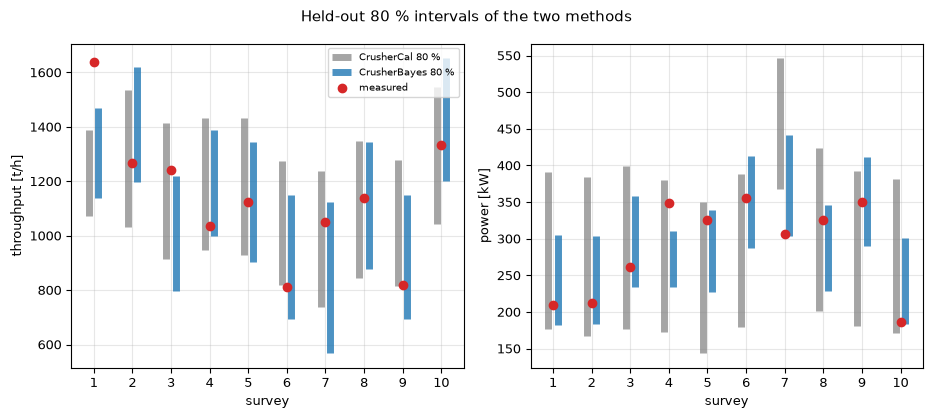

In [6]:

# The ten held-out predictions with the CrusherBayes interval, the CrusherCal band and the measured
# value
x = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2))
for ax, (name, key), ylabel in zip(axes, targets, ('throughput [t/h]', 'power [kW]')):
    block = committed["loo"][name]
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    cc_lo, cc_hi = cc_band[name]
    ax.vlines(x - 0.12, cc_lo, cc_hi, color="tab:grey", lw=5, alpha=0.7, label='CrusherCal 80 %')
    ax.vlines(x + 0.12, lo, hi, color="tab:blue", lw=5, alpha=0.8, label='CrusherBayes 80 %')
    ax.scatter(x, block["measured"], color="tab:red", zorder=3, label='measured')
    ax.set_xticks(x)
    ax.set_xlabel('survey')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Held-out 80 % intervals of the two methods')
fig.tight_layout()
plt.show()


CrusherBayes's intervals are narrower than CrusherCal's on both targets: a mean width of 439 t/h against 474 on the throughput (93 percent of the band) and 118 kW against 210 on the power (56 percent). The narrowing on the power is the real gain, since the backbone's power band is as wide as the measured range itself. The coverage of CrusherBayes is 0.8 on the throughput and 0.9 on the power (8 and 9 surveys of 10 inside), with survey 1, 3 outside on the throughput and survey 4 on the power; CrusherCal's nested band covers 0.8 and 0.9. With ten surveys one survey moves a coverage by 0.1, so these coverages cannot be told from the nominal 0.8 and the figure says nothing more about calibration than that it is plausible. It does not say that a sharper interval is a better predictor: B-lin's own interval, computed the same way, is 120 kW wide on the power, as sharp as CrusherBayes's.

The same residual-band rule that sizes CrusherCal's band can be applied to CrusherBayes's own held-out residuals, to ask whether the posterior interval is any better than a band built from the errors of its point predictions: the cell sizes each survey's band from the other nine residuals, as notebook 04 of topic 06 does.

In [7]:

# CrusherCal's own nested-band rule applied to CrusherBayes's held-out residuals, for both targets
nested_cb = {}
for name, key in targets:
    block = committed["loo"][name]
    resid = np.array(block["measured"]) - np.array(block["pred_mean"])
    nested = loo.nested_band_coverage(resid)
    width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
    nested_cb[name] = (nested["coverage"], width)
    print((
    '{:5s} CrusherBayes residuals, nested band: coverage {:.2f}, '
    'mean width {:7.1f}'
).format(name, nested["coverage"], width))


tph   CrusherBayes residuals, nested band: coverage 0.80, mean width   451.5
kW    CrusherBayes residuals, nested band: coverage 0.80, mean width   119.3


For a fair width comparison the cell below gives B-lin and the free-form regression the same nested band.

In [8]:

# The same nested band for B-lin and for the free-form regression, to compare the widths of the three
for name, key in targets:
    strict = crushercal["loo"][key]["strict"]
    measured = np.array(crushercal["loo"][key]["measured"])
    for model in ("B_lin", "M2"):
        nested = loo.nested_band_coverage(measured - np.array(strict["pred"][model]))
        width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
        text = '{:5s} {:6s} nested band: coverage {:.2f}, mean width {:7.1f}'
        print(text.format(name, model, nested["coverage"], width))


tph   B_lin  nested band: coverage 0.80, mean width   478.8
tph   M2     nested band: coverage 0.80, mean width   468.5
kW    B_lin  nested band: coverage 0.80, mean width   119.6
kW    M2     nested band: coverage 0.80, mean width   129.8


Last, the in-sample form of the rule, with sigma from all ten residuals, set against the posterior interval of CrusherBayes.

In [9]:

# The in-sample band of CrusherBayes's residuals, sigma from all ten, against its own posterior
# interval
for name, key in targets:
    block = committed["loo"][name]
    band = loo.predictive_band(np.array(block["measured"]) - np.array(block["pred_mean"]))
    posterior_width = np.mean(np.array(block["hi80"]) - np.array(block["lo80"]))
    print((
    '{:5s} in-sample CrusherCal rule on CrusherBayes residuals: '
    'width {:7.1f}; posterior interval: width {:7.1f}'
).format(name, 2 * band["halfwidth"], posterior_width))


tph   in-sample CrusherCal rule on CrusherBayes residuals: width   452.4; posterior interval: width   439.1
kW    in-sample CrusherCal rule on CrusherBayes residuals: width   119.6; posterior interval: width   117.7


Given the same rule, CrusherBayes's residuals give a nested band of 119 kW on the power (coverage 0.8) and 451 t/h on the throughput (coverage 0.8), against 120 kW and 479 t/h for B-lin and 130 kW and 469 t/h for the free-form regression. On the power the three narrow models lie between 119 and 130 kW and are all far below the backbone's 210 kW: the narrowing is the gain of having any model that follows the setting, and CrusherBayes does not narrow it further than a line does. The in-sample form gives 120 kW against the posterior interval's 118 kW, so the posterior interval is about as wide as a residual band of its own errors would be.

## Evidence

**What the surveys identify.** A posterior can be as wide as its prior for a parameter the data do not constrain. The contraction, the posterior standard deviation over the prior one, measures it for the fit to all ten surveys: below about 0.5 the surveys identify the parameter, near 1 they leave it where it started. The cell lists every parameter, sorted, from the committed document.

In [10]:

# The contraction table of the fit to all ten surveys, sorted, with the identification line at 0.5
table = sorted(committed["contraction"], key=lambda row: row["contraction"])
for row in table:
    print(f"{row['name']:26s} nominal {row['nominal']:8.2f}  posterior {row['posterior_mean']:9.2f} ", end="")
    print(f"sd {row['posterior_sd']:8.3f}  contraction {row['contraction']:.2f}")


sigma_tph                  nominal    60.00  posterior    145.23 sd   39.037  contraction 0.30
sigma_kW                   nominal    15.00  posterior     38.81 sd   10.754  contraction 0.33
discrepancy_tph_f80        nominal     0.00  posterior     56.57 sd   47.627  contraction 0.34
discrepancy_tph_css        nominal     0.00  posterior    100.84 sd   48.996  contraction 0.35
discrepancy_kW_f80         nominal     0.00  posterior     -5.16 sd   13.026  contraction 0.36
discrepancy_kW_css         nominal     0.00  posterior    -57.07 sd   13.704  contraction 0.38
q_ref_tph                  nominal   647.00  posterior    646.35 sd   75.745  contraction 0.45
zeta                       nominal     1.30  posterior      1.14 sd    0.223  contraction 0.73
pn_kw                      nominal   110.00  posterior     86.35 sd   38.039  contraction 0.80
wi_kwh_t                   nominal     9.00  posterior      8.39 sd    1.294  contraction 0.85
discrepancy_tph_constant   nominal     0.00  poste

The figure draws the same table as bars, with the identification line at 0.5 and the prior at 1.

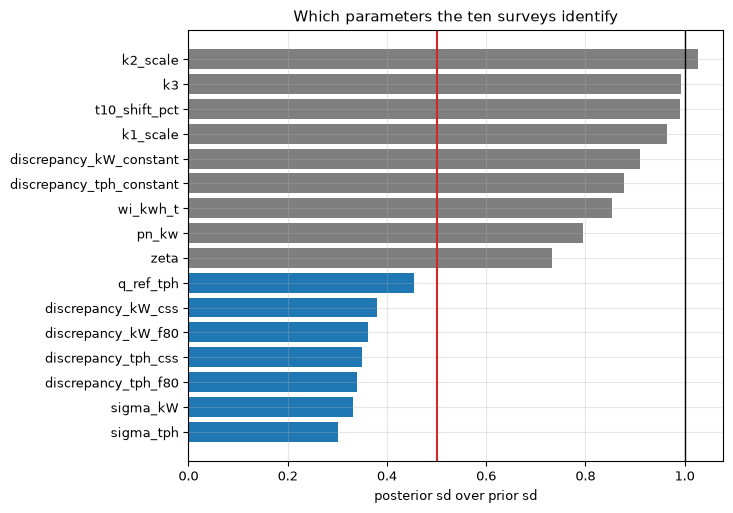

In [11]:

# Posterior over prior standard deviation of every parameter, from the document
fig, ax = plt.subplots(figsize=(7.4, 5.2))
names = [row["name"] for row in table]
values = [row["contraction"] for row in table]
ax.barh(names, values, color=["tab:blue" if v < 0.5 else "tab:grey" for v in values])
ax.axvline(0.5, color="tab:red", lw=1.5)
ax.axvline(1.0, color="black", lw=1)
ax.set_xlabel('posterior sd over prior sd')
ax.set_title('Which parameters the ten surveys identify')
fig.tight_layout()
plt.show()


7 of the 16 parameters fall below 0.5: q_ref_tph, sigma_tph, sigma_kW, discrepancy_tph_css, discrepancy_tph_f80, discrepancy_kW_css, discrepancy_kW_f80. They are the capacity base (the one scalar that moves the throughput, notebook 01), the two noise scales and the discrepancy slopes on the setting and on the feed f80. Everything else stays above 0.7, close to its prior or only slightly narrowed: `zeta` at 0.73, `wi_kwh_t` at 0.85, `pn_kw` at 0.80, and `k1_scale`, `k2_scale`, `k3` and `t10_shift_pct` at 0.96, 1.03, 0.99 and 0.99, the constants of the discrepancy at 0.91 and 0.88. The ten surveys therefore do not determine the Andersen constants K1, K2 and K3 or the t10 shift of the classification and breakage models: the posterior of those scalars is their prior, and a prediction that depends on them is carried by the discrepancy instead. This is a result about the data, not a flaw of the sampler. The figure does not show whether more surveys would identify them; it shows that these ten, which vary only the setting and the feed size over narrow ranges, do not.

**The kill criterion.** The rule is applied with the module's own function, from the scores and interval widths computed in this notebook, term by term.

In [12]:

# The kill criterion of the SDD, evaluated with the module's function on the numbers computed above
verdict = cb.kill_criterion(
    power_mape=cb_score["kW"]["mape"], power_mape_blin=comparator_mape["kW"]["B_lin"],
    tph_mape=cb_score["tph"]["mape"], tph_mape_m0=comparator_mape["tph"]["M0"],
    coverage={t: cb_score[t]["coverage"] for t in ("tph", "kW")},
    width={t: cb_score[t]["width"] for t in ("tph", "kW")},
    width_crushercal={t: np.mean(cc_band[t][1] - cc_band[t][0]) for t in ("tph", "kW")})
v = verdict
print((
    '(a) power MAPE {:.2f} % against B-lin {:.2f} %: gain {:+.2f} '
    'points, needed 3.0 -> beats by the margin: {}'
).format(v["power_mape_pct"], v["power_mape_blin_pct"],
                     v["power_gain_over_blin_pts"], v["a_power_beats_blin_by_margin"]))
print((
    '(a) throughput MAPE {:.2f} % against the backbone {:.2f} %: '
    'gain {:+.2f} points -> beats by the margin: {}'
).format(v["tph_mape_pct"], v["tph_mape_m0_pct"],
                     v["tph_gain_over_m0_pts"], v["a_tph_beats_m0_by_margin"]))
print((
    '(a) holds, that is neither beats its comparator by the margin: '
    '{}'
).format(v["a_holds"]))
print((
    '(b) coverage {} outside 0.7 to 0.9: {} | band wider than '
    "CrusherCal's: {} -> (b) holds: {}"
).format(v["coverage"], v["coverage_outside_band"],
                     v["band_wider_than_crushercal"], v["b_holds"]))
print('verdict: {}'.format(v["verdict"]))


(a) power MAPE 14.31 % against B-lin 12.78 %: gain -1.54 points, needed 3.0 -> beats by the margin: False
(a) throughput MAPE 12.00 % against the backbone 12.09 %: gain +0.09 points -> beats by the margin: False
(a) holds, that is neither beats its comparator by the margin: True
(b) coverage {'tph': np.float64(0.8), 'kW': np.float64(0.9)} outside 0.7 to 0.9: {'tph': False, 'kW': False} | band wider than CrusherCal's: {'tph': False, 'kW': False} -> (b) holds: False
verdict: kept


Part (a) of the rule holds: the power gain over B-lin is -1.54 points, negative, where 9.78 percent (B-lin's 12.78 less the margin) would have been needed, and the throughput gain over the backbone is +0.09 points against the 3 required. Part (b) does not hold: both coverages lie inside 0.7 to 0.9 and both bands are narrower than CrusherCal's. The rule drops the method only when (a) and (b) both hold, so the verdict is **kept**: CrusherBayes stays in the product as a predictor, because its interval is sharper and calibrated within what ten surveys can show, although it does not beat B-lin on the power. The criterion also says that even then the identifiability table is the result, and that is the section above. The one reproduction check of the notebook follows: the scores and the verdict recomputed here against the committed document.

In [13]:

# The one reproduction check: the scores and the verdict recomputed here against the committed
# document
doc_kc = committed["kill_criterion"]
scores_equal = all(abs(cb_score[t]["mape"] - committed["loo"][t]["scores"]["mape_pct"]) < 0.01 for t in ("tph", "kW"))
print((
    "scores equal the document: {} | verdict equals the document's "
    '({}): {}'
).format(scores_equal, doc_kc["verdict"], verdict["verdict"] == doc_kc["verdict"]))


scores equal the document: True | verdict equals the document's (kept): True


**What the convergence record shows.** The committed chains are the longest the bake runs, and the document records for each posterior whether the sampler passed its own diagnostic, a chain of at least 50 autocorrelation times. The cell prints that record.

In [14]:

# The convergence record of the committed chains
print('posterior   tau [steps]   chain over tau   converged')
for row in record:
    print(f"{row['fold']!s:9s} {row['tau_max']:12.1f} {row['chain_over_tau']:16.1f} {row['converged']!s:>11}")


posterior   tau [steps]   chain over tau   converged
1                 52.6            114.1        True
2                 52.7            113.8        True
3                 54.7            109.7        True
4                 84.8             70.7        True
5                 52.7            113.9        True
6                 48.0            125.0        True
7                 55.1            108.9        True
8                 48.9            122.7        True
9                 52.6            114.1        True
10                50.7            118.3        True
all               48.6            123.5        True


11 of the 11 posteriors pass: the chains of 7000 steps have autocorrelation times of 48 to 85 steps and lengths of 70.7 to 125.0 times that, above the 50 the pipeline requires, with the differential-evolution moves of ter Braak (2006) and ter Braak and Vrugt (2008) that the sampler uses (an earlier bake with the stretch move did not reach it). The scores above are therefore estimates from chains that passed the sampler's own diagnostic. That is a statement about the chains and not a proof of convergence: the diagnostic is one criterion, and ten surveys leave the weakly identified parameters wide whatever the chain length, so the contraction ratios near 1 mean the data do not constrain them, not that the sampler failed.

## Results

**Answer:** CrusherBayes gives a sharper interval than the CrusherCal band and keeps its coverage, but it does not predict the power better than B-lin, and the criterion keeps it. Held out on the ten surveys it has a power error of 14.31 percent against 12.78 for B-lin (1.54 points behind) and 25.94 for the backbone, and a throughput error of 12.00 percent against 12.09 for the backbone, a gain of 0.09 points that ten surveys cannot tell from zero. Its 80 percent intervals are 118 kW and 439 t/h wide against 210 kW and 474 t/h for CrusherCal, with 9 and 8 surveys of 10 inside. The surveys identify the capacity base (contraction 0.45), the noise and the discrepancy slopes, and leave K1, K2, K3 and the t10 shift at their prior (contraction 0.96 to 1.03). The kill criterion, recomputed here from the notebook's own numbers, gives the verdict kept that the document records, because part (b) does not hold. The chains passed their own diagnostic in 11 of 11 posteriors, at 70.7 to 125.0 autocorrelation times.

## Summary

CrusherBayes is measured here against the criterion that was written before it ran. It improves what the product already had, the width of the predictive interval, and it cuts the backbone's power error from 25.94 to 14.29 percent, but the simplest competitor, a line on the setting, predicts the power as well or better, and the method does not claim otherwise. What it adds that no point fit gives is the identifiability table: with ten surveys of one machine the data say what the capacity and the noise are and say nothing about the classification and breakage constants. The result stands on chains that passed their convergence diagnostic in all eleven posteriors, so the contraction ratios can be quoted as measured, within what ten surveys can show.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- ter Braak, C. J. F. (2006), A Markov chain Monte Carlo version of the genetic algorithm differential evolution, Statistics and Computing 16, 239-249. https://doi.org/10.1007/s11222-006-8769-1
- ter Braak, C. J. F., Vrugt, J. A. (2008), Differential evolution Markov chain with snooker updater and fewer chains, Statistics and Computing 18, 435-446. https://doi.org/10.1007/s11222-008-9104-9